# libraries import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Dataset load

In [2]:
df=pd.read_csv('amazonreviews.tsv', sep="\t")
df

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."
...,...,...
9995,pos,A revelation of life in small town America in ...
9996,pos,Great biography of a very interesting journali...
9997,neg,Interesting Subject; Poor Presentation: You'd ...
9998,neg,Don't buy: The box looked used and it is obvio...


## Data understanding

In [3]:
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


In [4]:
df.tail()

,label,review
9995,pos,A revelation of life in small town America in ...
9996,pos,Great biography of a very interesting journali...
9997,neg,Interesting Subject; Poor Presentation: You'd ...
9998,neg,Don't buy: The box looked used and it is obvio...
9999,pos,Beautiful Pen and Fast Delivery.: The pen was ...


In [5]:
df.shape

(10000, 2)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


In [7]:
df.columns

Index(['label', 'review'], dtype='object')

In [8]:
df.isnull().sum()

label     0
review    0
dtype: int64

In [9]:
df['label'].value_counts()

label
neg    5097
pos    4903
Name: count, dtype: int64

## EDA

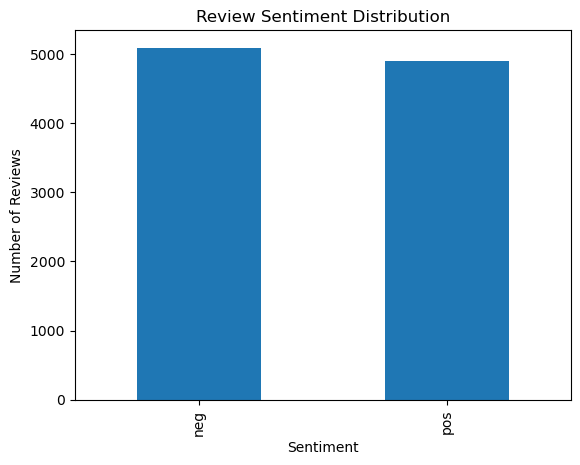

In [10]:
df['label'].value_counts().plot(kind='bar')

plt.title("Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [11]:
df['review_length'] = df['review'].str.len()

In [12]:
df['review_length'].describe()

count    10000.000000
mean       438.695400
std        239.241132
min        101.000000
25%        238.000000
50%        391.000000
75%        605.000000
max       1015.000000
Name: review_length, dtype: float64

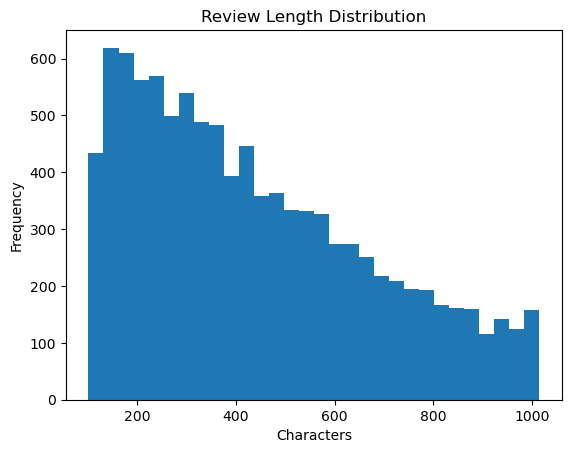

In [13]:
plt.hist(df['review_length'], bins=30)

plt.title("Review Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.show()

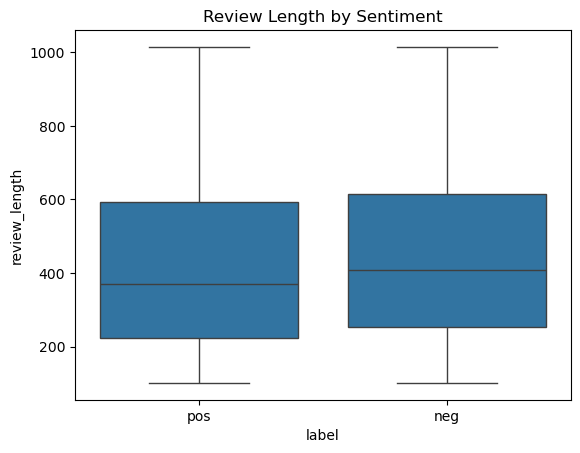

In [14]:
sns.boxplot(
    x='label',
    y='review_length',
    data=df
)

plt.title("Review Length by Sentiment")
plt.show()

## Text Preprocessing

In [15]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

In [16]:
df['clean_review'] = df['review'].apply(clean_text)

In [17]:
df[['review', 'clean_review']].head()

,review,clean_review
0,Stuning even for the non-gamer: This sound tra...,stuning even for the nongamer this sound track...
1,The best soundtrack ever to anything.: I'm rea...,the best soundtrack ever to anything im readin...
2,Amazing!: This soundtrack is my favorite music...,amazing this soundtrack is my favorite music o...
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack i truly like this soundtr...
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull your jaw off the floor after hea...


## Train test

In [18]:
from sklearn.model_selection import train_test_split

X = df['clean_review']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 8000
Testing samples: 2000


## TFIDF Vectorization

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [21]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (8000, 10000)
Testing TF-IDF shape: (2000, 10000)


## Logistic Regression model train

In [22]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_tfidf, y_train)

log_pred = log_model.predict(X_test_tfidf)

In [23]:
print(log_pred[:10])

['neg' 'pos' 'neg' 'pos' 'neg' 'neg' 'neg' 'neg' 'pos' 'pos']


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, log_pred))
print("Precision:", precision_score(y_test, log_pred, pos_label='pos'))
print("Recall:", recall_score(y_test, log_pred, pos_label='pos'))
print("F1 Score:", f1_score(y_test, log_pred, pos_label='pos'))

print("\nClassification Report:\n")
print(classification_report(y_test, log_pred))

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, log_pred))

Accuracy: 0.856
Precision: 0.8524923702950152
Recall: 0.854230377166157
F1 Score: 0.8533604887983707

Classification Report:

              precision    recall  f1-score   support

         neg       0.86      0.86      0.86      1019
         pos       0.85      0.85      0.85       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000


Confusion Matrix:

[[874 145]
 [143 838]]


In [25]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

In [26]:
print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.861

Classification Report:

              precision    recall  f1-score   support

         neg       0.85      0.88      0.87      1019
         pos       0.87      0.84      0.86       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



In [27]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

In [28]:
print("Linear SVM Accuracy:", accuracy_score(y_test, svm_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, svm_pred))

Linear SVM Accuracy: 0.8645

Classification Report:

              precision    recall  f1-score   support

         neg       0.88      0.86      0.87      1019
         pos       0.85      0.87      0.86       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



In [29]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'Linear SVM'
    ],
    'Accuracy': [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, svm_pred)
    ]
})

results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,Linear SVM,0.8645
1,Naive Bayes,0.8610
0,Logistic Regression,0.8560


In [30]:
best_model = svm_model
best_pred = svm_pred

print("Best Model: Linear SVM")
print("Best Accuracy:", accuracy_score(y_test, best_pred))

Best Model: Linear SVM
Best Accuracy: 0.8645


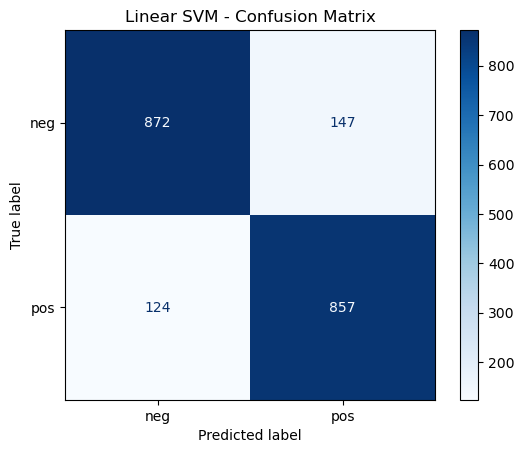

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    cmap='Blues'
)

plt.title("Linear SVM - Confusion Matrix")
plt.show()

In [32]:
error_df = pd.DataFrame({
    "review": X_test,
    "actual": y_test,
    "predicted": best_pred
})

error_df = error_df[error_df["actual"] != error_df["predicted"]]

error_df.head(10)

,review,actual,predicted
2240,interesting this was a very fascinating read i...,pos,neg
4888,second and last time around for sandisk e seri...,neg,pos
8173,creepy being a huge fan of the original i was ...,pos,neg
8349,wouldnt recommended this card worked great in ...,neg,pos
5501,one of my favorite toys this blue eyes shining...,neg,pos
5488,a picture book with great photos and interesti...,pos,neg
6065,whos laughing my husband and i are expecting o...,neg,pos
1910,king of sleeze of the s if you enjoy bad scrip...,pos,neg
3694,why not spanish alguien me puede decir porque ...,neg,pos
1105,dont listen to the others absolutely awfuli wa...,neg,pos


In [33]:
print("Total misclassified reviews:", len(error_df))

Total misclassified reviews: 271


In [34]:
for i, row in error_df.head(5).iterrows():
    print("Review:", row["review"])
    print("Actual:", row["actual"])
    print("Predicted:", row["predicted"])
    print("-" * 80)

Review: interesting this was a very fascinating read it does not focus only on mothamn sightings but all the other strange events that were supposed to have happened if you are looking for a book that will prove mothman exists i dont think this is the proper book for you it is mainly about what went on from the first sighting of mothman to the felling of the bridge there were a lot of strange happenings during that time i read this as im presenting you with the information as to what heppened as i saw it and was involved in it and you make up your mind as to whether its true or not
Actual: pos
Predicted: neg
--------------------------------------------------------------------------------
Review: second and last time around for sandisk e series this is my second sansa e series mp player the first was a rhapsody edition and lasted about months i blamed the short life on the r series and since i liked the way it looked and worked thought i would try it again with the e i loaded up my gig 

In [35]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    best_pred,
    target_names=["Negative", "Positive"]
))

              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87      1019
    Positive       0.85      0.87      0.86       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



In [36]:
from sklearn.pipeline import Pipeline
import joblib

final_pipeline = Pipeline([
    ("tfidf", tfidf),
    ("model", best_model)
])

In [37]:
joblib.dump(final_pipeline, "smart_review_svm_pipeline.pkl")

['smart_review_svm_pipeline.pkl']

In [38]:
loaded_pipeline = joblib.load("smart_review_svm_pipeline.pkl")

sample_review = [
    "This product is amazing and works perfectly"
]

prediction = loaded_pipeline.predict(sample_review)

print("Prediction:", prediction[0])

Prediction: pos


In [39]:
test_reviews = [
    "This product is excellent and I am very happy with the purchase.",
    "The product is terrible and stopped working after one day.",
    "The quality is okay but not very impressive.",
    "Amazing product, totally worth the money.",
    "Waste of money. I do not recommend this product."
]

predictions = loaded_pipeline.predict(test_reviews)

for review, prediction in zip(test_reviews, predictions):
    print("Review:", review)
    print("Sentiment:", prediction)
    print("-" * 80)

Review: This product is excellent and I am very happy with the purchase.
Sentiment: pos
--------------------------------------------------------------------------------
Review: The product is terrible and stopped working after one day.
Sentiment: neg
--------------------------------------------------------------------------------
Review: The quality is okay but not very impressive.
Sentiment: neg
--------------------------------------------------------------------------------
Review: Amazing product, totally worth the money.
Sentiment: pos
--------------------------------------------------------------------------------
Review: Waste of money. I do not recommend this product.
Sentiment: neg
--------------------------------------------------------------------------------


In [40]:
def predict_sentiment(review):
    prediction = loaded_pipeline.predict([review])[0]

    if prediction == "pos":
        return "Positive"
    else:
        return "Negative"

In [41]:
review = input("Enter your review: ")

result = predict_sentiment(review)

print("Predicted Sentiment:", result)

Enter your review:  The product quality is very good


Predicted Sentiment: Positive
